# ANALISIS SEGEMENTASI PELANGGAN

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from scipy.spatial.distance import cdist


In [28]:
# ===========================================
# IMPORT DATA
# ===========================================

# Membaca data dari file CSV
file_path = "C:/Users/user/Downloads/MY MAGANG 5/DATA TELKOMSEL/EVENTS/output EVENTS alls.csv"

# Pastikan untuk menyesuaikan delimiter jika berbeda
data = pd.read_csv(file_path, sep=';')

# Menghapus kolom 'OMSET TOTAL.1' langsung
data.drop(columns=['OMSET TOTAL.1'], inplace=True)
display(data)

# Mengisi nilai yang hilang dengan 0
data.fillna(0, inplace=True)

# Menghapus data duplikat
data.drop_duplicates(inplace=True)

# Pastikan kolom numerik dalam format yang sesuai (jika diperlukan)
num_cols = ['DS RATIO (%)', 'ACTUAL CALL (%)']  # Sesuaikan dengan dataset
for col in num_cols:
    if col in data.columns:
        data[col] = pd.to_numeric(data[col], errors='coerce').fillna(0)

# Membulatkan nilai kolom persentase dan mengubah tipe datanya menjadi integer
if 'DS RATIO (%)' in data.columns:
    data['DS RATIO (%)'] = data['DS RATIO (%)'].round().astype(int)
if 'ACTUAL CALL (%)' in data.columns:
    data['ACTUAL CALL (%)'] = data['ACTUAL CALL (%)'].round().astype(int)
    
# Membuat kolom baru untuk menghitung rasio pelanggan aktif
data['ACTIVE RATIO'] = data['DS ACTIVE'] / data['DS TOTAL']

data

,AREA,REGIONAL,BRANCH,CLUSTER,CITY,DS TOTAL,DS ACTIVE,DS RATIO (%),OMSET TRX DIGITAL,OMSET TOTAL,...,PLAN POI,ACTUAL POI,PLAN EVENT,ACTUAL EVENT,ACTUAL CALL (%),SALES,OTA,SALES ORBIT,VF,TRX DIGITAL
0,JAWA - BALI - NUSRA,BALI NUSRA,DENPASAR,BALI BARAT,BULELENG,42,3,7.1,39,11043601,...,49,37,72,50,69.0,0,0,0,0,29
1,JAWA - BALI - NUSRA,BALI NUSRA,DENPASAR,BALI BARAT,JEMBRANA,23,3,13.0,39,14135322,...,48,43,75,56,75.0,0,0,0,0,30
2,JAWA - BALI - NUSRA,BALI NUSRA,DENPASAR,BALI BARAT,TABANAN,20,3,15.0,37,8446941,...,50,46,53,48,91.0,5,0,0,0,36
3,JAWA - BALI - NUSRA,BALI NUSRA,DENPASAR,BALI TENGAH,BADUNG,42,6,14.3,92,24862947,...,116,77,156,100,64.0,59,0,0,125,89
4,JAWA - BALI - NUSRA,BALI NUSRA,DENPASAR,BALI TENGAH,KOTA DENPASAR,107,6,5.6,84,32561574,...,32,29,152,105,69.0,6,0,0,38,80
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1066,JAWA - BALI - NUSRA,JATIM,SURABAYA,KOTA SURABAYA,KOTA SURABAYA,197,13,6.6,18,9563982,...,45,43,51,49,96.0,24,0,0,0,18
1067,JAWA - BALI - NUSRA,JATIM,SURABAYA,MADURA,BANGKALAN,36,4,11.1,0,3282292,...,1,1,4,4,100.0,0,0,0,0,0
1068,JAWA - BALI - NUSRA,JATIM,SURABAYA,MADURA,PAMEKASAN,32,4,12.5,0,3308591,...,1,1,4,4,100.0,11,0,0,0,0
1069,JAWA - BALI - NUSRA,JATIM,SURABAYA,MADURA,SAMPANG,24,4,16.7,0,1364900,...,2,1,5,4,80.0,37,0,0,0,0


,AREA,REGIONAL,BRANCH,CLUSTER,CITY,DS TOTAL,DS ACTIVE,DS RATIO (%),OMSET TRX DIGITAL,OMSET TOTAL,...,ACTUAL POI,PLAN EVENT,ACTUAL EVENT,ACTUAL CALL (%),SALES,OTA,SALES ORBIT,VF,TRX DIGITAL,ACTIVE RATIO
0,JAWA - BALI - NUSRA,BALI NUSRA,DENPASAR,BALI BARAT,BULELENG,42,3,7,39,11043601,...,37,72,50,69,0,0,0,0,29,0.071429
1,JAWA - BALI - NUSRA,BALI NUSRA,DENPASAR,BALI BARAT,JEMBRANA,23,3,13,39,14135322,...,43,75,56,75,0,0,0,0,30,0.130435
2,JAWA - BALI - NUSRA,BALI NUSRA,DENPASAR,BALI BARAT,TABANAN,20,3,15,37,8446941,...,46,53,48,91,5,0,0,0,36,0.150000
3,JAWA - BALI - NUSRA,BALI NUSRA,DENPASAR,BALI TENGAH,BADUNG,42,6,14,92,24862947,...,77,156,100,64,59,0,0,125,89,0.142857
4,JAWA - BALI - NUSRA,BALI NUSRA,DENPASAR,BALI TENGAH,KOTA DENPASAR,107,6,6,84,32561574,...,29,152,105,69,6,0,0,38,80,0.056075
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1066,JAWA - BALI - NUSRA,JATIM,SURABAYA,KOTA SURABAYA,KOTA SURABAYA,197,13,7,18,9563982,...,43,51,49,96,24,0,0,0,18,0.065990
1067,JAWA - BALI - NUSRA,JATIM,SURABAYA,MADURA,BANGKALAN,36,4,11,0,3282292,...,1,4,4,100,0,0,0,0,0,0.111111
1068,JAWA - BALI - NUSRA,JATIM,SURABAYA,MADURA,PAMEKASAN,32,4,12,0,3308591,...,1,4,4,100,11,0,0,0,0,0.125000
1069,JAWA - BALI - NUSRA,JATIM,SURABAYA,MADURA,SAMPANG,24,4,17,0,1364900,...,1,5,4,80,37,0,0,0,0,0.166667


In [29]:
# ===========================================
# MENDETEKSI OUTLIER
# ===========================================

# Fungsi untuk mendeteksi outlier menggunakan IQR
def detect_outliers_iqr(data, col):
    Q1 = data[col].quantile(0.25)  # Kuartil pertama
    Q3 = data[col].quantile(0.75)  # Kuartil ketiga
    IQR = Q3 - Q1  # Rentang antar kuartil
    lower_bound = Q1 - 1.5 * IQR  # Batas bawah
    upper_bound = Q3 + 1.5 * IQR  # Batas atas
    return (data[col] < lower_bound) | (data[col] > upper_bound)  # Mask untuk outlier

# Kolom yang ingin diperiksa untuk outlier (sesuaikan dengan dataset)
numeric_cols = [
    'DS TOTAL', 'DS ACTIVE', 'DS RATIO (%)', 'OMSET TRX DIGITAL', 'OMSET TOTAL',
    'OMSET DATA', 'OMSET DIGITAL', 'OMSET RECHARGE', 'OMSET OTHER', 'PLAN POI',
    'ACTUAL POI', 'PLAN EVENT', 'ACTUAL EVENT', 'ACTUAL CALL (%)', 'SALES',
    'OTA', 'SALES ORBIT', 'VF', 'TRX DIGITAL'
]

# Mengecek dan menampilkan jumlah outlier per kolom
for col in numeric_cols:
    if col in data.columns:
        outliers = detect_outliers_iqr(data, col)
        print(f"Jumlah Outlier di kolom '{col}': {outliers.sum()}")
        
# ===========================================
# MENANGANI OUTLIER
# ===========================================

# Menangani outlier menggunakan Winsorization
def winsorize(data, col):
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Membatasi nilai di bawah batas bawah dan di atas batas atas
    data[col] = np.clip(data[col], lower_bound, upper_bound)

# Menerapkan Winsorization untuk setiap kolom numerik
for col in numeric_cols:
    if col in data.columns:
        winsorize(data, col)
        
# Mengecek dan menampilkan jumlah outlier per kolom setelah ditangani
for col in numeric_cols:
    if col in data.columns:
        outliers = detect_outliers_iqr(data, col)
        print(f"Jumlah Outlier di kolom '{col}' setelah ditangani: {outliers.sum()}")
        
# Mengubah kolom numerik yang sudah dibersihkan menjadi integer
for col in numeric_cols:
    if col in data.columns:
        data[col] = data[col].astype('int64')
# Menampilkan deskripsi statistik awal dataset
print("\nStatistik Deskriptif Data:")
display(data.describe())



Jumlah Outlier di kolom 'DS TOTAL': 72
Jumlah Outlier di kolom 'DS ACTIVE': 58
Jumlah Outlier di kolom 'DS RATIO (%)': 37
Jumlah Outlier di kolom 'OMSET TRX DIGITAL': 155
Jumlah Outlier di kolom 'OMSET TOTAL': 92
Jumlah Outlier di kolom 'OMSET DATA': 108
Jumlah Outlier di kolom 'OMSET DIGITAL': 120
Jumlah Outlier di kolom 'OMSET RECHARGE': 128
Jumlah Outlier di kolom 'OMSET OTHER': 127
Jumlah Outlier di kolom 'PLAN POI': 53
Jumlah Outlier di kolom 'ACTUAL POI': 59
Jumlah Outlier di kolom 'PLAN EVENT': 60
Jumlah Outlier di kolom 'ACTUAL EVENT': 70
Jumlah Outlier di kolom 'ACTUAL CALL (%)': 22
Jumlah Outlier di kolom 'SALES': 86
Jumlah Outlier di kolom 'OTA': 0
Jumlah Outlier di kolom 'SALES ORBIT': 0
Jumlah Outlier di kolom 'VF': 188
Jumlah Outlier di kolom 'TRX DIGITAL': 134
Jumlah Outlier di kolom 'DS TOTAL' setelah ditangani: 0
Jumlah Outlier di kolom 'DS ACTIVE' setelah ditangani: 0
Jumlah Outlier di kolom 'DS RATIO (%)' setelah ditangani: 0
Jumlah Outlier di kolom 'OMSET TRX DIGITA

,DS TOTAL,DS ACTIVE,DS RATIO (%),OMSET TRX DIGITAL,OMSET TOTAL,OMSET DATA,OMSET DIGITAL,OMSET RECHARGE,OMSET OTHER,PLAN POI,ACTUAL POI,PLAN EVENT,ACTUAL EVENT,ACTUAL CALL (%),SALES,OTA,SALES ORBIT,VF,TRX DIGITAL,ACTIVE RATIO
count,1063.000000,1063.000000,1063.000000,1063.000000,1.063000e+03,1.063000e+03,1063.000000,1.063000e+03,1.063000e+03,1063.000000,1063.000000,1063.000000,1063.000000,1063.000000,1063.000000,1063.0,1063.0,1063.0,1063.000000,1063.000000
mean,23.034807,3.844779,18.038570,7.018815,1.490695e+07,4.534603e+06,161066.751646,3.119645e+06,4.194086e+06,45.971778,40.132643,71.228598,57.382879,83.566322,138.873942,0.0,0.0,0.0,9.193791,0.185090
std,11.424019,1.931352,8.146691,10.039452,1.583193e+07,5.042405e+06,214112.173169,3.642846e+06,4.878701e+06,37.622382,31.887017,46.502672,35.812721,13.866768,169.829967,0.0,0.0,0.0,12.709416,0.097071
min,3.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,45.000000,0.000000,0.0,0.0,0.0,0.000000,0.000000
25%,14.000000,3.000000,12.000000,0.000000,2.892525e+06,7.163250e+05,0.000000,3.325000e+05,4.876870e+05,16.000000,15.000000,40.000000,34.000000,75.000000,2.000000,0.0,0.0,0.0,0.000000,0.125000
50%,21.000000,3.000000,17.000000,1.000000,8.425475e+06,2.294630e+06,50660.000000,1.495000e+06,1.902339e+06,37.000000,32.000000,63.000000,51.000000,86.000000,62.000000,0.0,0.0,0.0,2.000000,0.166667
75%,28.000000,5.000000,23.000000,11.000000,2.191753e+07,6.657713e+06,245024.500000,4.488000e+06,6.161750e+06,66.000000,56.500000,95.000000,75.000000,95.000000,215.000000,0.0,0.0,0.0,14.000000,0.230769
max,49.000000,8.000000,39.000000,27.000000,5.045504e+07,1.556980e+07,612561.000000,1.072125e+07,1.467284e+07,141.000000,118.000000,177.000000,136.000000,100.000000,534.000000,0.0,0.0,0.0,35.000000,0.750000


REGIONAL
BALI NUSRA    361
JATENG-DIY    360
JATIM         342
Name: count, dtype: int64

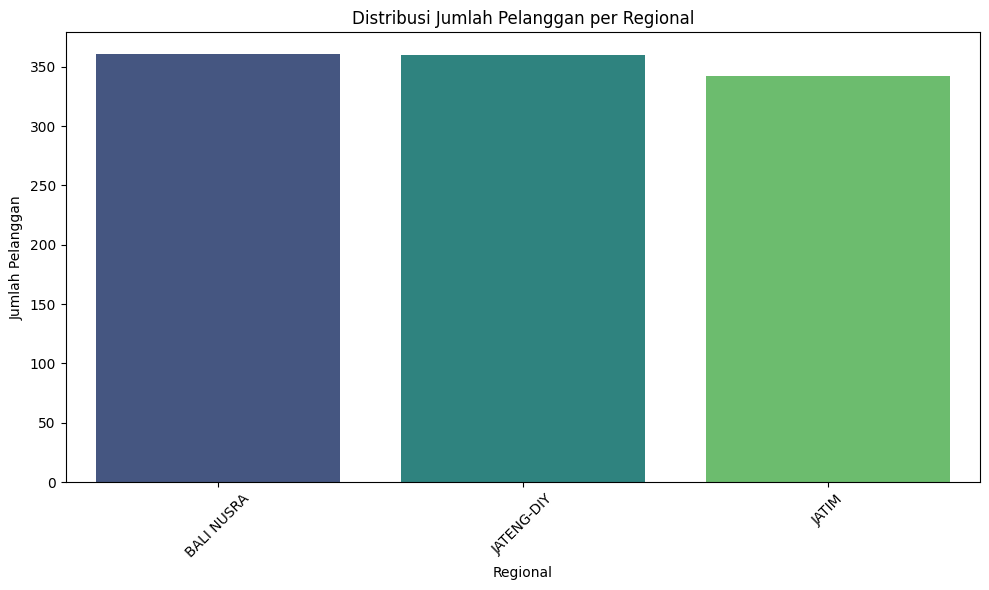

BRANCH
KUPANG        100
FLORES         90
MATARAM        90
MADIUN         90
DENPASAR       81
SEMARANG       81
SURAKARTA      81
PEKALONGAN     72
JEMBER         63
MAGELANG       54
MALANG         54
SIDOARJO       54
SURABAYA       45
PURWOKERTO     36
YOGYAKARTA     36
LAMONGAN       36
Name: count, dtype: int64

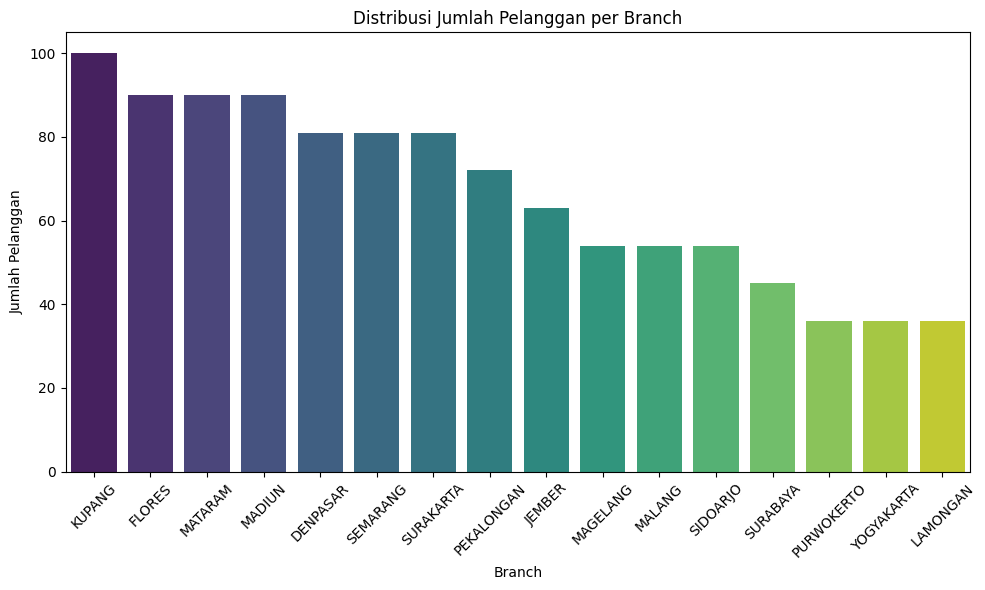

CLUSTER
LOMBOK                45
MANGGARAI             45
SUMBA                 37
MALAKA TIMTIM BELU    36
YOGYAKARTA            36
MADIUN                36
MADURA                36
BALI TIMUR            36
TULUNGAGUNG           27
JOMBANG MOJOKERTO     27
Name: count, dtype: int64


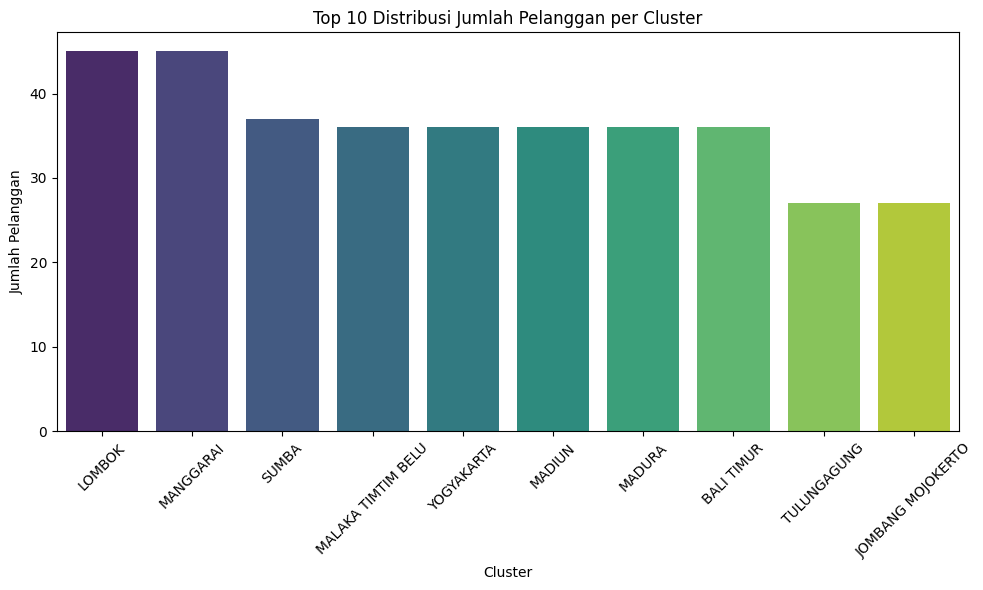

In [30]:
# ===========================================
# EDA GEOGRAFIS
# ===========================================

# Menghitung jumlah pelanggan per Regional
branch_counts = data['REGIONAL'].value_counts()
display(branch_counts)

# Membuat grafik batang
plt.figure(figsize=(10, 6))
sns.barplot(x=branch_counts.index,y=branch_counts.values, palette='viridis')

# Menambahkan label dan judul
plt.xlabel('Regional')
plt.ylabel('Jumlah Pelanggan')
plt.title('Distribusi Jumlah Pelanggan per Regional')
plt.xticks(rotation=45)  # Rotasi label sumbu x agar lebih mudah dibaca
plt.tight_layout()

# Menampilkan grafik
plt.show()

# Menghitung jumlah pelanggan per Branch
branch_counts = data['BRANCH'].value_counts()
display(branch_counts)

# Membuat grafik batang
plt.figure(figsize=(10, 6))
sns.barplot(x=branch_counts.index,y=branch_counts.values, palette='viridis')

# Menambahkan label dan judul
plt.xlabel('Branch')
plt.ylabel('Jumlah Pelanggan')
plt.title('Distribusi Jumlah Pelanggan per Branch')
plt.xticks(rotation=45)  
plt.tight_layout()

# Menampilkan grafik
plt.show()

# Menghitung jumlah pelanggan per Cluster
cluster_counts = data['CLUSTER'].value_counts().head(10)  
print(cluster_counts)

# Membuat grafik batang
plt.figure(figsize=(10, 6))
sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette='viridis')

# Menambahkan label dan judul
plt.xlabel('Cluster')
plt.ylabel('Jumlah Pelanggan')
plt.title('Top 10 Distribusi Jumlah Pelanggan per Cluster')
plt.xticks(rotation=45)  # Rotasi label sumbu x agar lebih mudah dibaca
plt.tight_layout()

# Menampilkan grafik
plt.show()


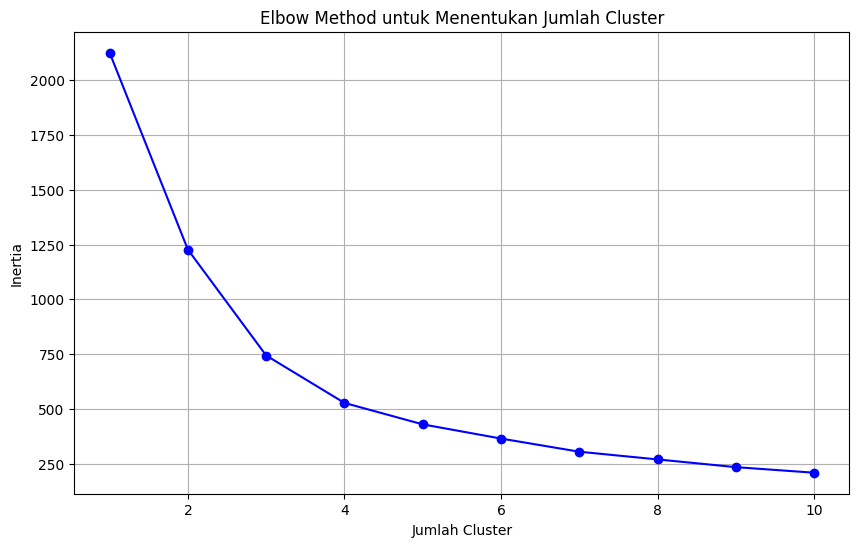

In [31]:
# ===========================================
# ELBHOW METHOD
# ===========================================

# Persiapan Data
# Memilih kolom yang relevan untuk clustering
try:
    features = data[['OMSET TOTAL', 'ACTIVE RATIO']]  
except KeyError as e:
    raise KeyError("Kolom yang dipilih tidak ditemukan dalam dataset: 'OMSET TOTAL' atau 'ACTIVE RATIO'")

# Normalisasi Data
# Standardisasi fitur agar skala variabel tidak mempengaruhi hasil clustering
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

# Menentukan Jumlah Cluster yang Optimal
# Elbow Method untuk menentukan jumlah cluster yang optimal
inertia = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(features_scaled)
    inertia.append(kmeans.inertia_)
    

# Visualisasi Elbow Method
plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), inertia, marker='o', color='b', label='Inertia')
plt.xlabel('Jumlah Cluster')
plt.ylabel('Inertia')
plt.title('Elbow Method untuk Menentukan Jumlah Cluster')
plt.grid(True)
plt.show()


In [32]:
# ===========================================
# JUMLAH CLUSTER TERBAIK
# ===========================================

# Menentukan jumlah cluster optimal
optimal_clusters = 3  

# Clustering dengan K-Means
kmeans = KMeans(n_clusters=optimal_clusters, random_state=42, n_init=10)
data['Cluster'] = kmeans.fit_predict(features_scaled)

# Menampilkan Hasil Clustering
print("\nHasil Clustering Pelanggan:")
display(data[['BRANCH', 'CLUSTER', 'CITY', 'Cluster']].head())

# Analisis Hasil Clustering
print("\nJumlah Pelanggan per Cluster:")
display(data['Cluster'].value_counts())



Hasil Clustering Pelanggan:


,BRANCH,CLUSTER,CITY,Cluster
0,DENPASAR,BALI BARAT,BULELENG,0
1,DENPASAR,BALI BARAT,JEMBRANA,0
2,DENPASAR,BALI BARAT,TABANAN,0
3,DENPASAR,BALI TENGAH,BADUNG,0
4,DENPASAR,BALI TENGAH,KOTA DENPASAR,1



Jumlah Pelanggan per Cluster:


Cluster
0    654
1    227
2    182
Name: count, dtype: int64

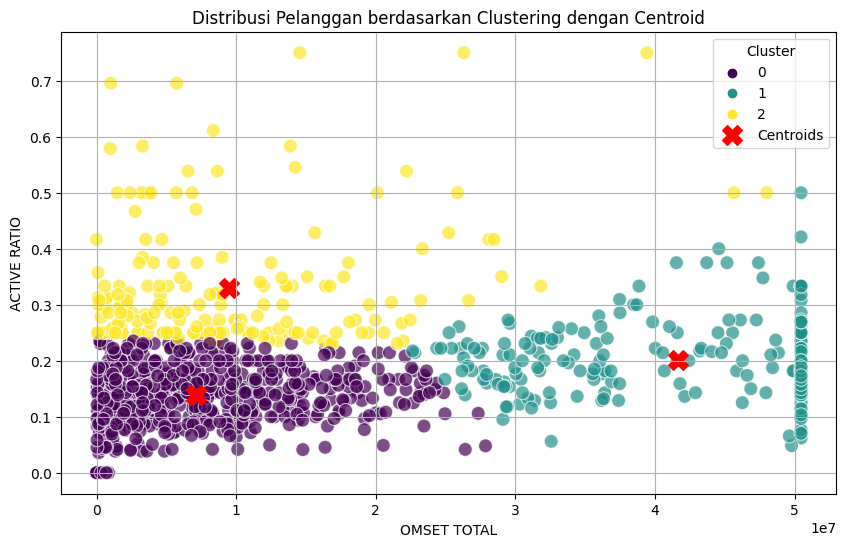

In [33]:
# ===========================================
# CENTROID
# ===========================================

# Ambil centroid dari model K-Means
centroids = kmeans.cluster_centers_

# Kembalikan centroid ke skala asli
centroids_original_scale = scaler.inverse_transform(centroids)  

# Visualisasi hasil clustering
plt.figure(figsize=(10, 6))

# Scatter plot untuk data
sns.scatterplot(
    x=data['OMSET TOTAL'], 
    y=data['ACTIVE RATIO'], 
    hue=data['Cluster'], 
    palette='viridis', 
    s=100, 
    alpha=0.7
)

# Tambahkan centroid ke dalam plot
plt.scatter(
    centroids_original_scale[:, 0], 
    centroids_original_scale[:, 1], 
    c='red', 
    s=200, 
    marker='X', 
    label='Centroids'
)

# Tambahkan elemen visual lainnya
plt.title('Distribusi Pelanggan berdasarkan Clustering dengan Centroid')
plt.xlabel('OMSET TOTAL')
plt.ylabel('ACTIVE RATIO')
plt.legend(title='Cluster', loc='best')
plt.grid(True)

# Tampilkan plot
plt.show()


In [34]:
# ===========================================
# EVALUASI MODEL
# ===========================================

# Evaluasi Model K-Means dengan Silhouette Score
from sklearn.metrics import silhouette_score

# Menghitung Silhouette Score
sil_score = silhouette_score(features_scaled, data['Cluster'])

# Menampilkan hasil Silhouette Score
print(f"Silhouette Score: {sil_score:.4f}")

# Kesimpulan berdasarkan nilai Silhouette Score
if sil_score > 0.5:
    print("Model clustering bagus! Cluster terpisah dengan jelas dan berbeda.")
elif sil_score > 0:
    print("Model clustering dapat diterima. Ada beberapa tumpang tindih antar cluster, tetapi masih bisa dibedakan.")
else:
    print("Model clustering buruk. Cluster tidak terpisah dengan baik, dan titik data mungkin masuk ke cluster yang salah.")


Silhouette Score: 0.5079
Model clustering bagus! Cluster terpisah dengan jelas dan berbeda.


In [35]:
# Penjelasan untuk Setiap Cluster
print("\nPenjelasan untuk Setiap Cluster:")

for cluster_id in range(optimal_clusters):
    cluster_data = data[data['Cluster'] == cluster_id]
    omset_mean = cluster_data[['OMSET TOTAL', 'ACTIVE RATIO']].mean()  # Mengambil rata-rata OMSET TOTAL dan ACTIVE RATIO
    omset_desc = "Tinggi" if omset_mean['OMSET TOTAL'] > data['OMSET TOTAL'].mean() else "Rendah"
    
    print(f"\nCluster {cluster_id}:")
    print(f"- Rata-rata OMSET TOTAL: {omset_mean['OMSET TOTAL']:.2f} ({omset_desc})")
    print(f"- Rata-rata ACTIVE RATIO: {omset_mean['ACTIVE RATIO']:.2f}")
    
    if omset_desc == "Tinggi":
        print("- Cluster ini memiliki potensi tinggi berdasarkan OMSET TOTAL.")
    else:
        print("- Cluster ini memiliki potensi rendah berdasarkan OMSET TOTAL.")



Penjelasan untuk Setiap Cluster:

Cluster 0:
- Rata-rata OMSET TOTAL: 7126530.36 (Rendah)
- Rata-rata ACTIVE RATIO: 0.14
- Cluster ini memiliki potensi rendah berdasarkan OMSET TOTAL.

Cluster 1:
- Rata-rata OMSET TOTAL: 41639655.48 (Tinggi)
- Rata-rata ACTIVE RATIO: 0.20
- Cluster ini memiliki potensi tinggi berdasarkan OMSET TOTAL.

Cluster 2:
- Rata-rata OMSET TOTAL: 9522700.51 (Rendah)
- Rata-rata ACTIVE RATIO: 0.33
- Cluster ini memiliki potensi rendah berdasarkan OMSET TOTAL.


In [36]:
# ===========================================
# VALIDASI MODEL
# ===========================================

# Validasi Pseudo F-statistic
# Menghitung Within-Cluster Sum of Squares (WCSS) dan Between-Cluster Sum of Squares (BCSS)
wcss = kmeans.inertia_  # WCSS sudah dihitung oleh K-Means
bcss = np.sum(cdist(features_scaled, centroids, 'euclidean')**2) - wcss

# Pseudo F-statistic
pseudo_f = (bcss / (optimal_clusters - 1)) / (wcss / (features_scaled.shape[0] - optimal_clusters))
print(f"\nPseudo F-statistic: {pseudo_f:.4f}")

# Evaluasi Pseudo F-statistic
if pseudo_f > 1:
    print("Cluster dianggap sangat baik berdasarkan Pseudo F-statistic.")
elif pseudo_f > 0.5:
    print("Cluster cukup baik, tetapi ada kemungkinan untuk meningkatkan kualitas clustering.")
else:
    print("Cluster kurang baik berdasarkan Pseudo F-statistic.")



Pseudo F-statistic: 8319.1676
Cluster dianggap sangat baik berdasarkan Pseudo F-statistic.


In [37]:
# Strategi Pemetaan Target Konsumen
strategies = {}

# Menentukan strategi berdasarkan cluster
for cluster_id in range(optimal_clusters):
    cluster_data = data[data['Cluster'] == cluster_id]
    omset_mean = cluster_data[['OMSET TOTAL', 'ACTIVE RATIO']].mean()  # Mengambil rata-rata OMSET TOTAL dan ACTIVE RATIO
    omset_desc = "Tinggi" if omset_mean['OMSET TOTAL'] > data['OMSET TOTAL'].mean() else "Rendah"
    
    # Menentukan strategi untuk setiap cluster
    if omset_desc == "Tinggi":
        if omset_mean['ACTIVE RATIO'] > data['ACTIVE RATIO'].mean():
            strategies[cluster_id] = "Fokus pada retensi pelanggan melalui program loyalitas, peningkatan produk, dan peningkatan kualitas layanan."
        else:
            strategies[cluster_id] = "Fokus pada promosi yang meningkatkan engagement untuk mempertahankan omzet tinggi."
    else:
        if omset_mean['ACTIVE RATIO'] > data['ACTIVE RATIO'].mean():
            strategies[cluster_id] = "Fokus pada peningkatan omzet melalui penawaran khusus dan promosi untuk mendorong aktivitas lebih tinggi."
        else:
            strategies[cluster_id] = "Fokus pada segmentasi ulang dengan memberikan tawaran produk yang lebih relevan atau peningkatan layanan."

# Menampilkan strategi untuk setiap cluster
print("\nStrategi untuk Setiap Cluster:")
for cluster_id, strategy in strategies.items():
    print(f"\nCluster {cluster_id}: {strategy}")



Strategi untuk Setiap Cluster:

Cluster 0: Fokus pada segmentasi ulang dengan memberikan tawaran produk yang lebih relevan atau peningkatan layanan.

Cluster 1: Fokus pada retensi pelanggan melalui program loyalitas, peningkatan produk, dan peningkatan kualitas layanan.

Cluster 2: Fokus pada peningkatan omzet melalui penawaran khusus dan promosi untuk mendorong aktivitas lebih tinggi.


In [38]:
# Implementasi Strategi dalam Pemetaan Target Konsumen
# Mengidentifikasi konsumen dalam cluster tertentu untuk pemasaran terarah
target_consumer_map = {}
for cluster_id in range(optimal_clusters):
    target_consumers = data[data['Cluster'] == cluster_id]
    target_consumer_map[cluster_id] = target_consumers[['BRANCH', 'CLUSTER', 'CITY', 'OMSET TOTAL', 'ACTIVE RATIO']]

# Menampilkan konsumen yang akan menjadi target strategi
print("\nPemetaan Target Konsumen Berdasarkan Cluster:")
for cluster_id, target_consumers in target_consumer_map.items():
    print(f"\nCluster {cluster_id}:")
    display(target_consumers.head())



Pemetaan Target Konsumen Berdasarkan Cluster:

Cluster 0:


,BRANCH,CLUSTER,CITY,OMSET TOTAL,ACTIVE RATIO
0,DENPASAR,BALI BARAT,BULELENG,11043601,0.071429
1,DENPASAR,BALI BARAT,JEMBRANA,14135322,0.130435
2,DENPASAR,BALI BARAT,TABANAN,8446941,0.150000
3,DENPASAR,BALI TENGAH,BADUNG,24862947,0.142857
5,DENPASAR,BALI TIMUR,BANGLI,14542815,0.120000



Cluster 1:


,BRANCH,CLUSTER,CITY,OMSET TOTAL,ACTIVE RATIO
4,DENPASAR,BALI TENGAH,KOTA DENPASAR,32561574,0.056075
9,FLORES,ENDE SIKKA,ENDE,50455035,0.200000
10,FLORES,ENDE SIKKA,SIKKA,50455035,0.173913
11,FLORES,FLORES TIMUR,ALOR,49888637,0.333333
12,FLORES,FLORES TIMUR,FLORES TIMUR,35801991,0.230769



Cluster 2:


,BRANCH,CLUSTER,CITY,OMSET TOTAL,ACTIVE RATIO
13,FLORES,FLORES TIMUR,LEMBATA,47998003,0.50
16,FLORES,MANGGARAI,MANGGARAI TIMUR,9070265,0.25
21,KUPANG,KUPANG ROTE,ROTE NDAO,7533238,0.25
22,KUPANG,MALAKA TIMTIM BELU,BELU,19468159,0.25
23,KUPANG,MALAKA TIMTIM BELU,MALAKA,25857025,0.50
